# Clínica de errores: auditar una medición antes de creerle

**Materiales desarrollados por Matías Barreto, 2026**

**Tecnicatura Superior en Ciencias de Datos e IA, IFTS24**
* **Nomenclatura oficial:** Procesamiento de Lenguaje Natural
* **Nombre de trabajo:** Laboratorio de PLN: Analítica, Textos y Cultura

---

## Objetivo

Auditar cinco mediciones sobre un mismo corpus de cuentos de Horacio Quiroga, encontrar el error de cada una y corregirlo con evidencia.

## Al terminar este cuaderno vamos a poder:

1. Verificar que una frecuencia relativa use el denominador correcto.
2. Validar un diccionario de palabras leyendo las concordancias que lo sostienen.
3. Distinguir lo frecuente de lo distintivo en TF-IDF y reconocer qué borran `max_features` y `min_df`.
4. Contrastar una conclusión escrita de antemano contra los datos, sin reemplazarla por la contraria.

> **El caso de hoy**
> Un equipo comparó dos libros de cuentos que Quiroga publicó hacia 1917 y 1918, uno para adultos y otro para niños, y presentó cinco resultados. Cada resultado tiene un error. Nuestra tarea es encontrarlo, probarlo y corregirlo.

## ◈ Marco contextual

Un resultado de análisis de texto casi nunca se ve mal: viene con tres decimales, un gráfico limpio y un título prolijo. Por eso conviene desconfiar de la prolijidad. Un ejemplo de este mismo cuaderno: según el cálculo del equipo, la palabra *monte* aparece más en los cuentos para adultos (0,76 por cada 1.000 palabras) que en los infantiles (0,52). Con el denominador correcto, la relación se invierte: 1,03 contra 1,99. Los dos resultados se ven igual de serios, y uno de ellos dice lo contrario de lo que pasa en los cuentos.

Esa es la tarea de hoy: ante un número que se ve bien, preguntar qué cuenta, sobre qué total y qué pasaría si cambiáramos un parámetro.

**Dónde se vuelve a ver.** Esta rutina de auditoría no es exclusiva del conteo de palabras. Cuando trabajemos con embeddings, clasificadores o sistemas de recuperación de información, cada resultado nuevo va a necesitar las mismas preguntas: qué mide realmente, sobre qué total y qué pasa si cambiamos un parámetro.

## ◈ Microglosario

| Término | Qué es en lenguaje llano |
|---|---|
| **Denominador** | El total contra el cual dividimos una cantidad para obtener una proporción. |
| **Frecuencia relativa** | Cuántas veces aparece una palabra en relación con el tamaño del texto; permite comparar textos de distinta longitud. |
| **Concordancia** | Cada aparición de una palabra mostrada con las palabras que la rodean. |
| **TF-IDF** | Un peso que sube cuando una palabra se repite en un texto y baja cuando aparece en muchos textos. |
| **Validez** | Que una medida mida realmente lo que decimos que mide. |

## Los datos

| Campo | Dato |
|---|---|
| Fuente | [Wikisource en español](https://es.wikisource.org), páginas de cada cuento de Horacio Quiroga |
| Período | Entre 1917 y 1918 según Wikisource (los dos volúmenes figuran como 1918) |
| Territorio | Literatura rioplatense; ambientación principal en Misiones |
| Unidad de análisis | Un cuento por fila |
| Cobertura | Los 18 cuentos que Wikisource lista para *Cuentos de amor de locura y de muerte* y los 8 de *Cuentos de la selva para los niños*. Quedan afuera el resto de los libros de Quiroga |
| Fecha de acceso | 5 de octubre de 2026 |
| Transformaciones previas | Se conservaron solo los párrafos del cuento; se restituyeron las letras capitulares; se perdieron los subtítulos internos |
| Limitaciones | Ortografía anterior a 1959 sin normalizar: la tilde de `fué` y `dió` hace que cuenten como palabras distintas de `fue` y `dio`; transcripciones colaborativas con posibles erratas; destinatario y género van juntos (los cuentos infantiles son fábulas con animales, los de adultos son relatos de terror y psicológicos), así que no podemos separar un efecto del otro; 26 cuentos son pocos para afirmar con firmeza |
| Licencia y ética | Obras en dominio público (Wikisource marca "80 p.m.a. o menos"); citamos la fuente; no hay datos personales |

**Nota:** el criterio que separa los dos grupos es externo al vocabulario: lo define el volumen en que Quiroga publicó cada cuento y su destinatario (adultos o niños).

### Configuración del entorno

In [1]:
# Importamos las librerías que usamos en todo el cuaderno.
import re
from collections import Counter

import numpy as np
import pandas as pd
import sklearn
import spacy
from sklearn.feature_extraction.text import TfidfVectorizer
from spacy.lang.es.stop_words import STOP_WORDS

import utils

Registramos las versiones de las librerías y fijamos la semilla: así sabemos en qué condiciones corrimos el cuaderno.

In [2]:
# La semilla fija el azar de dos pasos: elegir 4 cuentos al azar (caso 4)
# y desplazar un poco los puntos de los gráficos para que no se tapen.
SEMILLA = 42

print(f"pandas {pd.__version__}, numpy {np.__version__}, scikit-learn {sklearn.__version__}, spaCy {spacy.__version__}")
print(f"Semilla fijada en {SEMILLA} para los pasos con azar.")

pandas 3.0.6, numpy 2.5.3, scikit-learn 1.9.1, spaCy 3.8.7
Semilla fijada en 42 para los pasos con azar.


Ya tenemos el entorno. Ahora cargamos el corpus: un archivo con un cuento por línea. Esperamos 26 filas.

In [3]:
RUTA_DEL_CORPUS = "corpus.jsonl"

try:
    corpus = pd.read_json(RUTA_DEL_CORPUS, lines=True)
except FileNotFoundError:
    print(f"No encontramos {RUTA_DEL_CORPUS}. Revisen que esté en la misma carpeta que este cuaderno.")

print(f"Forma de la tabla: {corpus.shape}")
columnas_a_mostrar = ["id", "titulo", "volumen", "grupo", "palabras"]
display(corpus[columnas_a_mostrar].head(5))

Forma de la tabla: (26, 10)


,id,titulo,volumen,grupo,palabras
0,adulto_01,A la deriva,Cuentos de amor de locura y de muerte,adulto,1057
1,adulto_02,El alambre de púa,Cuentos de amor de locura y de muerte,adulto,3325
2,adulto_03,El almohadón de pluma,Cuentos de amor de locura y de muerte,adulto,1197
3,adulto_04,El infierno artificial,Cuentos de amor de locura y de muerte,adulto,2450
4,adulto_05,El perro rabioso,Cuentos de amor de locura y de muerte,adulto,2677


Cada fila es un cuento. La columna `grupo` contiene la comparación que nos interesa: `adulto` frente a `infantil`. La columna `palabras` es la cantidad de palabras que registró el archivo al armarse. Guardemos esa cifra en la memoria: va a reaparecer.

In [4]:
cuentos_por_grupo = corpus.groupby("grupo").agg(
    cuentos=("id", "count"),
    palabras_del_archivo=("palabras", "sum"),
)
display(cuentos_por_grupo)

assert len(corpus) == 26, "El corpus debería tener 26 cuentos: 18 del volumen adulto y 8 del infantil."

,cuentos,palabras_del_archivo
grupo,,
adulto,18,49271
infantil,8,17625


- **Observación:** hay 18 cuentos en el grupo adulto y 8 en el infantil; el grupo adulto suma casi el triple de palabras.
- **Interpretación:** los grupos tienen tamaños muy distintos, y eso va a importar cada vez que comparemos cantidades.
- **Límite:** esta tabla describe el corpus, no dice nada todavía sobre el vocabulario de cada grupo.

## Cómo trabajamos cada caso

Cada caso sigue la misma secuencia, y la vamos a repetir cinco veces:

| Paso | Qué hacemos |
|---|---|
| Síntoma | Mostramos un resultado que parece razonable. |
| Sospecha | Conversamos: ¿qué podría estar mal? |
| Prueba | Escribimos una verificación corta que lo demuestre. |
| Corrección | Arreglamos el cálculo y dejamos una aserción que lo controla. |
| Regla | Nos llevamos una pregunta para auditar mediciones futuras. |

## Antes de los casos: ¿qué es una palabra?

Para contar palabras hay que decidir qué cuenta como palabra. Esa decisión es nuestra, no del texto. Probemos un criterio simple sobre una frase de *A la deriva*: pasar todo a minúscula y quedarnos con las secuencias de letras.

In [5]:
frase_de_ejemplo = "El hombre pisó algo blanduzco, y enseguida sintió la mordedura. ¡Fué un dolor agudo!"

frase_en_minuscula = frase_de_ejemplo.lower()

# 'findall' devuelve todas las secuencias que cumplen el patrón.
# El patrón [a-záéíóúüñ]+ significa: una o más letras, con tildes, diéresis y eñe.
palabras_de_la_frase = re.findall(r"[a-záéíóúüñ]+", frase_en_minuscula)

print(palabras_de_la_frase)

['el', 'hombre', 'pisó', 'algo', 'blanduzco', 'y', 'enseguida', 'sintió', 'la', 'mordedura', 'fué', 'un', 'dolor', 'agudo']


- **Observación:** quedaron 14 palabras; los signos de puntuación y las mayúsculas desaparecieron.
- **Interpretación:** con este criterio, `Fué` y `fué` cuentan como la misma palabra, pero `fué` y `fue` seguirán siendo distintas.
- **Límite:** el criterio no normaliza la ortografía de época; lo retomamos en la práctica final.

Ahora que el paso a paso está claro, lo guardamos en una función con nombre y lo aplicamos a los 26 cuentos.

In [6]:
def separar_palabras(texto):
    """Recibe un texto y devuelve la lista de sus palabras, en minúscula y sin signos."""
    texto_en_minuscula = texto.lower()
    palabras = re.findall(r"[a-záéíóúüñ]+", texto_en_minuscula)
    return palabras


corpus["palabras_del_cuento"] = corpus["texto"].apply(separar_palabras)
corpus["cantidad_de_palabras"] = corpus["palabras_del_cuento"].apply(len)

Comparemos ahora las dos cifras que tenemos para el mismo texto: la del archivo y la que acabamos de calcular nosotros.

In [7]:
totales_por_grupo = corpus.groupby("grupo").agg(
    palabras_del_archivo=("palabras", "sum"),
    palabras_por_letras=("cantidad_de_palabras", "sum"),
)
display(totales_por_grupo)

,palabras_del_archivo,palabras_por_letras
grupo,,
adulto,49271,49749
infantil,17625,17573


- **Observación:** para el mismo texto hay dos totales distintos, y la diferencia ni siquiera tiene el mismo signo en los dos grupos.
- **Interpretación:** el archivo contó por espacios y nosotros por letras; ninguna cifra es "la correcta", pero cada una responde a un criterio.
- **Límite:** lo que no podemos hacer es mezclarlas. Si el numerador se cuenta con un criterio, el denominador tiene que usar el mismo. Esa idea es el centro del primer caso.

## Caso 1: el denominador

**Síntoma.** El equipo quiere comparar qué tan frecuentes son algunas palabras en cada volumen. Como los grupos tienen tamaños distintos, calculó frecuencias relativas: cada cantidad dividida por un total, expresada por cada 1.000 palabras.

**Un caso resuelto con una sola palabra.** *monte* aparece 51 veces en el volumen adulto (49.749 palabras) y 35 veces en el infantil (17.573 palabras). Con las cantidades crudas, el adulto parece ganar (51 contra 35). Si dividimos cada cantidad por el total **de su propio grupo**, el resultado es 1,03 y 1,99 por cada 1.000 palabras, y gana el infantil. Si dividimos las dos por el total **del corpus** (67.322 palabras), obtenemos 0,76 y 0,52: se conserva el orden de las cantidades crudas y se pierde la comparación.

**Bajada tecnológica.** Normalizar por tamaño reaparece en casi toda métrica de análisis de datos, desde tasas de error de un modelo hasta casos cada 100.000 habitantes.

Primero reunimos las palabras de cada grupo y las contamos.

In [8]:
# Reunimos todas las palabras de cada grupo en una sola lista.
palabras_por_grupo = {"adulto": [], "infantil": []}

for cuento in corpus.to_dict(orient="records"):
    grupo = cuento["grupo"]
    palabras_por_grupo[grupo].extend(cuento["palabras_del_cuento"])

# 'Counter' cuenta cuántas veces aparece cada palabra de una lista.
conteos_por_grupo = {}
for grupo in palabras_por_grupo:
    conteos_por_grupo[grupo] = Counter(palabras_por_grupo[grupo])

Calculamos también cuántas palabras tiene cada grupo y el corpus completo: son los totales que vamos a usar como denominadores.

In [9]:
total_del_corpus = 0
for grupo in palabras_por_grupo:
    total_del_grupo = len(palabras_por_grupo[grupo])
    total_del_corpus += total_del_grupo
    print(f"{grupo}: {total_del_grupo:,} palabras")
print(f"Corpus completo: {total_del_corpus:,} palabras")

adulto: 49,749 palabras
infantil: 17,573 palabras
Corpus completo: 67,322 palabras


Ahora el cálculo del equipo: cantidad de apariciones, dividida por el total, por cada 1.000 palabras.

In [10]:
PALABRAS_A_COMPARAR = ["tigre", "hombre", "mujer", "monte", "río"]

filas_incorrectas = []
for palabra in PALABRAS_A_COMPARAR:
    fila = {"palabra": palabra}
    for grupo in conteos_por_grupo:
        veces = conteos_por_grupo[grupo][palabra]
        fila[grupo] = 1000 * veces / total_del_corpus
    filas_incorrectas.append(fila)

frecuencias_incorrectas = pd.DataFrame(filas_incorrectas)
display(frecuencias_incorrectas.round(2))

,palabra,adulto,infantil
0,tigre,0.01,0.80
1,hombre,1.10,1.34
2,mujer,0.98,0.00
3,monte,0.76,0.52
4,río,0.37,0.71


Dibujamos esos valores tal como los presentó el equipo.

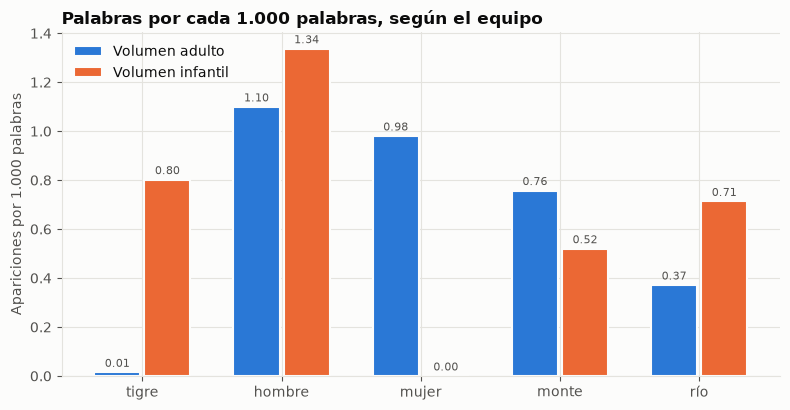

In [11]:
utils.graficar_barras_por_grupo(
    tabla=frecuencias_incorrectas,
    titulo="Palabras por cada 1.000 palabras, según el equipo",
    etiqueta_y="Apariciones por 1.000 palabras",
)

- **Observación:** el gráfico es limpio y se lee sin esfuerzo.
- **Interpretación:** nada en la imagen avisa que haya un problema; los números tienen decimales y los ejes tienen nombre.
- **Límite:** un gráfico prolijo no garantiza que el cálculo sea correcto.

### ✎ Laboratorio de rotura

Antes de ejecutar la celda siguiente, predigan: si sumamos las frecuencias relativas de **todas** las palabras distintas de un grupo, ¿cuánto debería dar el total? Anoten su respuesta antes de seguir.

Una frecuencia relativa bien calculada reparte el 100 % del texto entre todas sus palabras. Esa es nuestra prueba.

In [12]:
# Sumamos, para cada grupo, la frecuencia relativa del equipo de TODAS sus palabras.
for grupo in conteos_por_grupo:
    suma_de_frecuencias = 0
    for palabra in conteos_por_grupo[grupo]:
        veces = conteos_por_grupo[grupo][palabra]
        suma_de_frecuencias += veces / total_del_corpus
    print(f"{grupo}: las frecuencias suman {suma_de_frecuencias:.3f} (deberían sumar 1,000)")

adulto: las frecuencias suman 0.739 (deberían sumar 1,000)
infantil: las frecuencias suman 0.261 (deberían sumar 1,000)


- **Observación:** ningún grupo suma 1,000; el adulto queda en torno a 0,74 y el infantil en torno a 0,26.
- **Interpretación:** el equipo dividió por el total del **corpus** y no por el total de **cada grupo**. Al hacerlo, todos los valores se achican, y el grupo más corto se achica mucho más que el más largo. El error no solo cambia las cifras: distorsiona la comparación entre grupos.
- **Límite:** esta prueba detecta que el denominador está mal, pero no nos dice qué valores correctos habría que informar. Para eso hay que corregir.

**Corrección.** Cada grupo se divide por su propio total.

In [13]:
filas_correctas = []
for palabra in PALABRAS_A_COMPARAR:
    fila = {"palabra": palabra}
    for grupo in conteos_por_grupo:
        veces = conteos_por_grupo[grupo][palabra]
        total_del_grupo = len(palabras_por_grupo[grupo])
        fila[grupo] = 1000 * veces / total_del_grupo
    filas_correctas.append(fila)

frecuencias_correctas = pd.DataFrame(filas_correctas)
display(frecuencias_correctas.round(2))

,palabra,adulto,infantil
0,tigre,0.02,3.07
1,hombre,1.49,5.12
2,mujer,1.33,0.00
3,monte,1.03,1.99
4,río,0.50,2.73


Dejamos una aserción que controle lo que antes fallaba: ahora la suma de todas las frecuencias de un grupo tiene que dar 1.

In [14]:
for grupo in conteos_por_grupo:
    total_del_grupo = len(palabras_por_grupo[grupo])
    suma_de_frecuencias = 0
    for palabra in conteos_por_grupo[grupo]:
        veces = conteos_por_grupo[grupo][palabra]
        suma_de_frecuencias += veces / total_del_grupo
    assert abs(suma_de_frecuencias - 1) < 1e-9, f"En el grupo {grupo} las frecuencias deberían sumar 1."

print("Verificación superada: en cada grupo las frecuencias relativas suman 1.")

Verificación superada: en cada grupo las frecuencias relativas suman 1.


Ahora dibujamos los valores corregidos con el mismo gráfico.

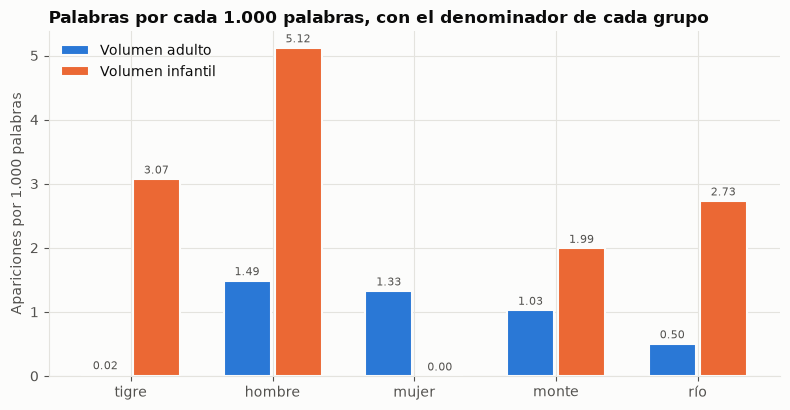

In [15]:
utils.graficar_barras_por_grupo(
    tabla=frecuencias_correctas,
    titulo="Palabras por cada 1.000 palabras, con el denominador de cada grupo",
    etiqueta_y="Apariciones por 1.000 palabras",
)

- **Observación:** con el denominador correcto, las barras del grupo infantil suben mucho más que las del adulto. `tigre` pasa de 0,80 a 3,07 por mil en el infantil, y `monte` cambia de lado: con el denominador del equipo parecía más frecuente en el grupo adulto (0,76 contra 0,52); con el correcto es al revés (1,03 contra 1,99).
- **Interpretación:** el error subestimaba sobre todo al grupo más corto, y en una palabra llegó a invertir la comparación.
- **Límite:** son cinco palabras elegidas a mano; la comparación no representa todo el vocabulario.

**Regla del caso 1:** antes de aceptar una frecuencia relativa, preguntar *¿sobre qué total está calculada?* y verificar que reparta el 100 %.

### ✎ Para pensar

- Si el grupo adulto hubiera sido el más corto, ¿el error habría favorecido o perjudicado al infantil?
- ¿Qué otro error de denominador podría aparecer si numerador y denominador usan criterios de conteo distintos, como vimos con el archivo y nuestra función?

## Caso 2: el diccionario

**Síntoma.** El equipo quiere medir cuánta "amenaza" hay en cada volumen. Armó un diccionario de palabras y contó, en cada cuento, cuántas aparecen por cada 1.000 palabras. Observen qué incluyó.

In [16]:
# Diccionario del equipo: palabras que, según su criterio, indican amenaza.
PALABRAS_DE_AMENAZA = [
    "peligro", "miedo", "amenaza", "atacar", "veneno",
    "tigre", "tigres", "víbora", "víboras", "yacaré", "yacarés",
]

Contamos, en cada cuento, cuántas palabras del diccionario aparecen por cada 1.000 palabras.

In [17]:
amenaza_por_cuento = []
for cuento in corpus.to_dict(orient="records"):
    palabras = cuento["palabras_del_cuento"]
    apariciones = 0
    for palabra in palabras:
        if palabra in PALABRAS_DE_AMENAZA:
            apariciones += 1
    fila = {"titulo": cuento["titulo"], "grupo": cuento["grupo"]}
    fila["amenaza"] = 1000 * apariciones / len(palabras)
    amenaza_por_cuento.append(fila)

tabla_amenaza = pd.DataFrame(amenaza_por_cuento)

### ✎ Antes de ejecutar

¿Qué volumen esperan que tenga más "amenaza", el de adultos o el de niños? Anoten la predicción y, sobre todo, la razón.

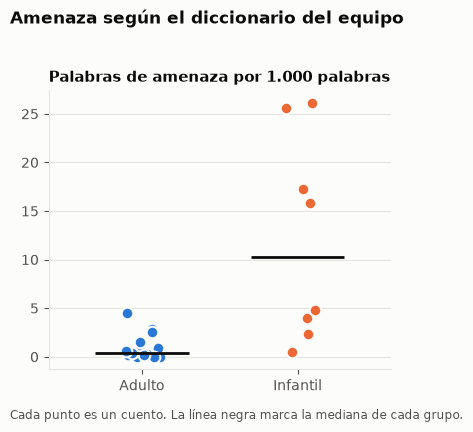

grupo
adulto       0.38
infantil    10.32
Name: amenaza, dtype: float64

In [18]:
utils.graficar_puntos_por_cuento(
    tabla=tabla_amenaza,
    columnas=["amenaza"],
    titulos=["Palabras de amenaza por 1.000 palabras"],
    titulo_general="Amenaza según el diccionario del equipo",
)

medianas_de_amenaza = tabla_amenaza.groupby("grupo")["amenaza"].median()
display(medianas_de_amenaza.round(2))

- **Observación:** la mediana del grupo infantil es 10,32 palabras de amenaza por cada 1.000, y la del adulto, 0,38.
- **Interpretación:** la conclusión del equipo sería que los cuentos para niños transmiten mucha más amenaza que los cuentos para adultos. Antes de aceptarla, hay que ver de dónde sale el puntaje.
- **Límite:** un puntaje alto indica que aparecen palabras del diccionario, no que haya amenaza.

**Prueba.** Desglosemos el aporte de cada palabra del diccionario.

In [19]:
filas_de_aporte = []
for palabra in PALABRAS_DE_AMENAZA:
    fila = {"palabra": palabra}
    for grupo in conteos_por_grupo:
        fila[grupo] = conteos_por_grupo[grupo][palabra]
    filas_de_aporte.append(fila)

aporte_por_palabra = pd.DataFrame(filas_de_aporte)
display(aporte_por_palabra)

,palabra,adulto,infantil
0,peligro,4,2
1,miedo,6,15
2,amenaza,2,0
3,atacar,0,0
4,veneno,3,6
5,tigre,1,54
6,tigres,1,34
7,víbora,5,6
8,víboras,12,34
9,yacaré,0,22


- **Observación:** casi todas las apariciones del grupo infantil vienen de nombres de animales: `tigre`, `tigres`, `yacarés`, `víboras`.
- **Interpretación:** el diccionario mezcla palabras de amenaza explícita (`peligro`, `miedo`) con nombres de fauna. Esa mezcla podría estar midiendo qué animales aparecen en el cuento, no cuánta amenaza hay.
- **Límite:** es una sospecha. Para convertirla en evidencia hay que leer las palabras en su contexto.

**La pregunta que contrasta.** Un diccionario cuenta formas, no sentidos. Cada aparición de `tigre`, ¿expresa una amenaza para los personajes, o es solo el nombre de un animal? El conteo no lo distingue; la frase donde aparece sí. 

**Bajada tecnológica.** En lingüística de corpus esta lectura se llama KWIC (palabra clave en contexto) y es la herramienta básica para validar cualquier diccionario.

Pedimos las concordancias de `tigre` y de `yacarés` en el volumen infantil: cada aparición con las palabras que la rodean.

In [20]:
es_infantil = corpus["grupo"] == "infantil"
textos_infantiles = corpus[es_infantil]["texto"]

for palabra_a_leer in ["tigre", "yacarés"]:
    fragmentos = []
    for texto in textos_infantiles:
        for coincidencia in re.finditer(rf"\b{palabra_a_leer}\b", texto):
            inicio = max(0, coincidencia.start() - 45)
            fin = coincidencia.end() + 45
            fragmentos.append(texto[inicio:fin].replace("\n", " "))

    # Tomamos un fragmento de cada ocho para ver contextos de distintos momentos.
    print(f"--- {palabra_a_leer} ---")
    for fragmento in fragmentos[::8][:4]:
        print("...", fragmento, "...")

--- tigre ---
... quellas dos luces verdes eran los ojos de un tigre que estaba agachado, mirándolo fijamente.  P ...
... ía.  —¡Más cer-ca! ¡No oi-go! — respondió el tigre con su ronca voz.  El loro se acercó un poco ...
... mo tiempo a todos lados, para ver si veía al tigre. Por fin sintió un ruido de ramas partidas,  ...
... taba también muy contento, porque matar a un tigre es cosa difícil, y además tenía la piel para ...
--- yacarés ---
... jar a beber, para estar seguro de que no hay yacarés.  Cada media hora hay que levantar bien alto ...
...  todos si el buque seguía pasando.  Pero los yacarés se echaron a reir, porque creyeran que el vi ...
...  día siguiente volvió el vapor, y cuando los yacarés miraron el buque, queduron mudos de asombro; ...
... ra vez, y el bote se acercó al dique.  —¡Eh, yacarés! — gritó el oficial.  —¡Qué hay! — respondie ...


- **Observación:** `tigre` aparece en general como amenaza concreta (unos ojos que acechan, una presa que huye). `yacarés`, en cambio, aparece como personajes que conversan, se ríen y se defienden.
- **Interpretación:** el diccionario cuenta igual al tigre que acecha y al yacaré que protagoniza el cuento. El puntaje mezcla amenaza con quiénes son los personajes.
- **Límite:** son ocho fragmentos; leerlos ilustra el problema, pero no mide cuánto pesa cada tipo de aparición.

**Corrección.** Separamos el diccionario en dos y medimos cada parte por su lado. Como ya entendemos el paso a paso, lo guardamos en una función.

In [21]:
def medir_diccionario(diccionario):
    """Devuelve, para cada cuento, cuántas palabras del diccionario aparecen por 1.000 palabras."""
    frecuencias = []
    for cuento in corpus.to_dict(orient="records"):
        palabras = cuento["palabras_del_cuento"]
        apariciones = 0
        for palabra in palabras:
            if palabra in diccionario:
                apariciones += 1
        frecuencias.append(1000 * apariciones / len(palabras))
    return frecuencias

Definimos las dos partes del diccionario y medimos cada una.

In [22]:
AMENAZA_EXPLÍCITA = ["peligro", "miedo", "amenaza", "atacar", "veneno"]
FAUNA_PELIGROSA = ["tigre", "tigres", "víbora", "víboras", "yacaré", "yacarés"]

tabla_separada = corpus[["titulo", "grupo"]].copy()
tabla_separada["amenaza_explícita"] = medir_diccionario(AMENAZA_EXPLÍCITA)
tabla_separada["fauna_peligrosa"] = medir_diccionario(FAUNA_PELIGROSA)

Comparamos las dos partes con el mismo tipo de gráfico y con las medianas de cada grupo.

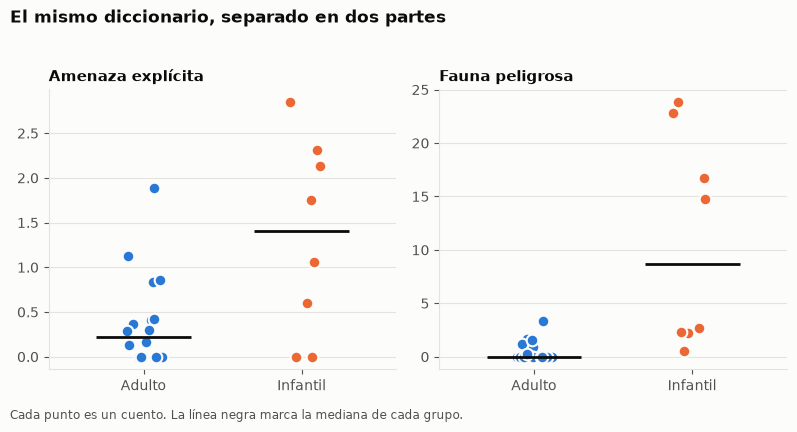

,amenaza_explícita,fauna_peligrosa
grupo,,
adulto,0.22,0.00
infantil,1.40,8.72


In [23]:
utils.graficar_puntos_por_cuento(
    tabla=tabla_separada,
    columnas=["amenaza_explícita", "fauna_peligrosa"],
    titulos=["Amenaza explícita", "Fauna peligrosa"],
    titulo_general="El mismo diccionario, separado en dos partes",
)

medianas_separadas = tabla_separada.groupby("grupo")[["amenaza_explícita", "fauna_peligrosa"]].median()
display(medianas_separadas.round(2))

- **Observación:** la fauna separa a los grupos casi por completo (mediana de 8,72 contra 0,00 por mil), mientras que la amenaza explícita los separa mucho menos (1,40 contra 0,22) y los rangos se superponen: de 0 a 1,89 en el adulto y de 0 a 2,85 en el infantil.
- **Interpretación:** gran parte del resultado original venía de que los cuentos infantiles nombran animales, es decir, del tema. La señal de amenaza explícita es más débil y menos concluyente.
- **Límite:** son cinco palabras con pocas apariciones por cuento; con tan poco material no corresponde afirmar nada firme sobre la amenaza.

**Regla del caso 2:** un diccionario se valida con ejemplos, no solo con el resultado. Hay que mirar qué palabras aportan y leerlas en contexto.

### ✎ Para pensar

- ¿Qué otras palabras del diccionario original podrían medir el tema en lugar de la postura?
- Si quisiéramos medir amenaza sin depender de palabras sueltas, ¿qué otra información del texto necesitaríamos?

## Caso 3: lo frecuente no es lo distintivo

**Síntoma.** El equipo quiere los términos más distintivos de cada volumen con TF-IDF. Pegó todos los cuentos de cada grupo en un solo texto y limitó el vocabulario a 30 términos.

**Definición operacional.** TF-IDF multiplica dos factores: TF, cuántas veces aparece el término en el texto, e IDF, que baja cuanto más textos contienen ese término. En scikit-learn, con la configuración por defecto, `idf = ln((1 + N) / (1 + df)) + 1`, donde `N` es la cantidad de textos y `df` en cuántos aparece el término. Con `N = 2`, un término presente en los dos textos recibe un IDF de 1,00 y uno presente en uno solo, 1,41. 

**Bajada tecnológica.** Es la base de los buscadores clásicos y de varios sistemas de recuperación de información que vamos a ver más adelante.

| Parámetro | Qué significa | Para qué lo usó el equipo | Qué cambia si lo modificamos |
|---|---|---|---|
| `max_features=30` | Se queda con los 30 términos más frecuentes de todo el corpus | Para obtener una lista corta | La lista final solo puede contener esos 30 términos, aunque haya otros más distintivos |

In [24]:
# Un "documento" por grupo: todos sus cuentos pegados en un solo texto.
textos_por_grupo = corpus.groupby("grupo")["texto"].apply(" ".join)

# 'tokenizer' le indica que use nuestra función; 'lowercase=False' evita pasar a
# minúscula dos veces, y 'token_pattern=None' desactiva el patrón que trae por defecto.
vectorizador_incorrecto = TfidfVectorizer(
    tokenizer=separar_palabras,
    token_pattern=None,
    lowercase=False,
    max_features=30,
)

# 'fit' aprende el vocabulario; 'transform' convierte los textos en pesos.
vectorizador_incorrecto.fit(textos_por_grupo)
pesos_por_grupo = vectorizador_incorrecto.transform(textos_por_grupo)

Veamos qué 30 términos quedaron y con qué peso en cada grupo.

In [25]:
pesos_densos = pesos_por_grupo.toarray()
términos_elegidos = vectorizador_incorrecto.get_feature_names_out()
tabla_de_pesos = pd.DataFrame(pesos_densos, index=textos_por_grupo.index, columns=términos_elegidos)
display(tabla_de_pesos.T.round(3))

grupo,adulto,infantil
a,0.276,0.282
al,0.095,0.105
como,0.046,0.067
con,0.132,0.113
de,0.500,0.396
del,0.073,0.082
el,0.312,0.363
en,0.249,0.193
es,0.053,0.059
había,0.051,0.054


### ✎ Antes de ejecutar

Miren la lista anterior. ¿Cuántos de esos 30 términos creen que son palabras vacías, como `de` o `la`?

**Prueba.** Contémoslas con la lista de palabras vacías del español que trae spaCy.

In [26]:
palabras_vacías_halladas = []
for término in términos_elegidos:
    if término in STOP_WORDS:
        palabras_vacías_halladas.append(término)

cantidad_de_términos = len(términos_elegidos)
cantidad_de_vacías = len(palabras_vacías_halladas)
print(f"De {cantidad_de_términos} términos «distintivos», {cantidad_de_vacías} son palabras vacías.")

De 30 términos «distintivos», 30 son palabras vacías.


- **Observación:** prácticamente toda la lista son palabras vacías.
- **Interpretación:** `max_features` elige los términos **más frecuentes del corpus** antes de ponderar nada. Las palabras vacías son las más frecuentes en cualquier texto, así que ocupan los 30 lugares y no queda espacio para ninguna palabra con contenido.
- **Límite:** que la lista sea inútil no significa que TF-IDF lo sea; el problema es qué le entregamos.

**Corrección.** Cambiamos dos decisiones. Primero, quitamos las palabras vacías y las de menos de tres letras. Segundo, la unidad de análisis deja de ser el grupo (2 documentos) y pasa a ser cada cuento (26 documentos). Dejamos el vocabulario completo, sin `max_features`.

In [27]:
def separar_palabras_con_contenido(texto):
    """Devuelve las palabras de un texto, sin palabras vacías y con al menos tres letras."""
    palabras_con_contenido = []
    for palabra in separar_palabras(texto):
        es_vacía = palabra in STOP_WORDS
        es_corta = len(palabra) < 3
        if not es_vacía and not es_corta:
            palabras_con_contenido.append(palabra)
    return palabras_con_contenido

Ahora armamos el vectorizador sobre los 26 cuentos, con esa función como criterio para separar palabras.

In [28]:
vectorizador_por_cuento = TfidfVectorizer(
    tokenizer=separar_palabras_con_contenido,
    token_pattern=None,
    lowercase=False,
)
vectorizador_por_cuento.fit(corpus["texto"])
pesos_por_cuento = vectorizador_por_cuento.transform(corpus["texto"])
print(f"Forma de la matriz: {pesos_por_cuento.shape} (cuentos por términos)")

Forma de la matriz: (26, 8870) (cuentos por términos)


Para comparar los grupos, promediamos el peso de cada término en los cuentos de cada grupo y miramos la diferencia.

In [29]:
vocabulario = vectorizador_por_cuento.get_feature_names_out()
pesos_por_término = pd.DataFrame(pesos_por_cuento.toarray(), columns=vocabulario)
pesos_por_término["grupo"] = corpus["grupo"]

peso_medio = pesos_por_término.groupby("grupo").mean()
peso_medio = peso_medio.T
peso_medio["diferencia"] = peso_medio["adulto"] - peso_medio["infantil"]
peso_medio = peso_medio.sort_values(by="diferencia")

print("Más distintivos del volumen infantil:")
display(peso_medio.head(8).round(3))
print("Más distintivos del volumen adulto:")
display(peso_medio.tail(8).round(3))

Más distintivos del volumen infantil:


grupo,adulto,infantil,diferencia
rayas,0.000,0.096,-0.096
tortuga,0.000,0.089,-0.089
gamita,0.000,0.079,-0.079
tigre,0.001,0.073,-0.072
pedrito,0.000,0.070,-0.070
abeja,0.000,0.070,-0.070
flamencos,0.000,0.069,-0.069
coaticito,0.000,0.064,-0.064


Más distintivos del volumen adulto:


grupo,adulto,infantil,diferencia
vezzera,0.033,0.0,0.033
míster,0.034,0.0,0.034
benincasa,0.035,0.0,0.035
amor,0.037,0.0,0.037
kassim,0.043,0.0,0.043
mujer,0.043,0.0,0.043
nébel,0.045,0.0,0.045
maría,0.057,0.0,0.057


- **Observación:** ahora los términos distintivos tienen contenido. Del lado infantil aparecen animales (`tortuga`, `abeja`, `flamencos`, `tigre`) y personajes (`pedrito`, `gamita`, `coaticito`). Del lado adulto, nombres propios (`vezzera`, `benincasa`, `kassim`, `nébel`, `maría`) y palabras como `amor` y `mujer`.
- **Interpretación:** lo distintivo en este corpus es sobre todo **quiénes aparecen en cada cuento** (especies, personajes, nombres propios), no cómo está escrito.
- **Límite:** que un término sea distintivo no dice por qué; con 26 cuentos, un nombre propio puede aparecer solo por un único cuento.

**Regla del caso 3:** frecuente no es distintivo. Antes de confiar en una lista de TF-IDF, preguntar *¿qué filtró el parámetro antes de ponderar?* y *¿cuáles son mis documentos?*

### ✎ Para pensar

- ¿Por qué `max_features` y `min_df` pueden distorsionar un ranking si actúan antes de que TF-IDF calcule los pesos?
- Si los términos distintivos son sobre todo nombres propios y fauna, ¿qué tipo de afirmaciones sobre estilo todavía no podemos hacer?

## Caso 4: pocos documentos y `min_df`

**Síntoma.** Otro equipo repitió el análisis con cuatro cuentos tomados al azar, para que "corriera más rápido". Y para eliminar ruido, descartó todo término que aparezca en un solo cuento.

| Parámetro | Qué significa | Para qué lo usó el equipo | Qué cambia si lo modificamos |
|---|---|---|---|
| `min_df=2` | Descarta los términos que aparecen en menos de 2 documentos | Para eliminar términos raros y errores de transcripción | También elimina todo lo que pertenece a un solo cuento, como nombres de personajes |

**Una consecuencia de la fórmula.** `df` solo puede valer 1, 2, …, `N`, así que el IDF toma como máximo `N` valores distintos. Con 4 cuentos, como máximo 4; con 26, hasta 26. Con pocos documentos casi todos los términos comparten el mismo IDF y el peso lo decide el TF.

Empecemos por el efecto de tener pocos documentos. Tomamos cuatro cuentos y calculamos el IDF, que es el componente de TF-IDF que depende de en cuántos documentos aparece cada término.

In [30]:
cuentos_al_azar = corpus.sample(n=4, random_state=SEMILLA)
títulos_elegidos = cuentos_al_azar["titulo"]
print(list(títulos_elegidos))

vectorizador_con_4 = TfidfVectorizer(
    tokenizer=separar_palabras_con_contenido,
    token_pattern=None,
    lowercase=False,
)
vectorizador_con_4.fit(cuentos_al_azar["texto"])
idf_con_4 = np.round(vectorizador_con_4.idf_, 3)
idf_con_26 = np.round(vectorizador_por_cuento.idf_, 3)

['La meningitis y su sombra', 'Una estación de amor', 'A la deriva', 'La tortuga gigante']


### ✎ Antes de ejecutar

Cada término tiene un IDF que depende de en cuántos documentos aparece. Si tenemos 4 documentos, ¿cuántos valores distintos de IDF puede haber? ¿Y con 26?

In [31]:
valores_distintos_con_4 = len(set(idf_con_4))
valores_distintos_con_26 = len(set(idf_con_26))

términos_con_4 = len(idf_con_4)
términos_con_26 = len(idf_con_26)

print(f"Con 4 cuentos: {valores_distintos_con_4} valores distintos de IDF para {términos_con_4:,} términos")
print(f"Con 26 cuentos: {valores_distintos_con_26} valores distintos de IDF para {términos_con_26:,} términos")

Con 4 cuentos: 4 valores distintos de IDF para 3,100 términos
Con 26 cuentos: 23 valores distintos de IDF para 8,870 términos


- **Observación:** con 4 documentos hay solo 4 valores distintos de IDF; con 26 documentos hay 23 (el máximo posible era 26).
- **Interpretación:** con pocos documentos casi todos los términos comparten el mismo IDF. Entonces el peso depende sobre todo de cuántas veces se repite el término en el cuento, es decir, TF-IDF se parece a un simple conteo.
- **Límite:** esto no depende de la calidad de los textos, sino de cuántos documentos tenemos.

Ahora el efecto de `min_df=2` sobre el corpus completo. Comparemos el vocabulario con y sin ese filtro.

In [32]:
vectorizador_min_df_2 = TfidfVectorizer(
    tokenizer=separar_palabras_con_contenido,
    token_pattern=None,
    lowercase=False,
    min_df=2,
)
vectorizador_min_df_2.fit(corpus["texto"])

vocabulario_con_1 = set(vectorizador_por_cuento.get_feature_names_out())
vocabulario_con_2 = set(vectorizador_min_df_2.get_feature_names_out())
términos_perdidos = vocabulario_con_1 - vocabulario_con_2

Comparamos los tamaños de los dos vocabularios.

In [33]:
cantidad_con_1 = len(vocabulario_con_1)
cantidad_con_2 = len(vocabulario_con_2)
proporción_perdida = len(términos_perdidos) / cantidad_con_1

print(f"Vocabulario con min_df=1: {cantidad_con_1:,} términos")
print(f"Vocabulario con min_df=2: {cantidad_con_2:,} términos")
print(f"El filtro descartó el {proporción_perdida:.0%} del vocabulario.")

Vocabulario con min_df=1: 8,870 términos
Vocabulario con min_df=2: 3,078 términos
El filtro descartó el 65% del vocabulario.


**Prueba.** ¿Qué nombres de personajes se perdieron? Los buscamos por nombre.

In [34]:
NOMBRES_A_BUSCAR = ["yaguaí", "maldana", "kassim", "pedrito", "alicia", "jordán"]

for nombre in NOMBRES_A_BUSCAR:
    está_con_1 = nombre in vocabulario_con_1
    está_con_2 = nombre in vocabulario_con_2
    print(f"{nombre}: con min_df=1 {está_con_1}, con min_df=2 {está_con_2}")

assert "yaguaí" in términos_perdidos, "Yaguaí debería haberse perdido con min_df=2: aparece en un solo cuento."

yaguaí: con min_df=1 True, con min_df=2 False
maldana: con min_df=1 True, con min_df=2 False
kassim: con min_df=1 True, con min_df=2 False
pedrito: con min_df=1 True, con min_df=2 False
alicia: con min_df=1 True, con min_df=2 False
jordán: con min_df=1 True, con min_df=2 False


- **Observación:** con `min_df=2` desaparece el 65 % del vocabulario, incluidos los nombres de personajes que aparecen en un solo cuento.
- **Interpretación:** esos nombres son justamente lo más distintivo de cada cuento. El filtro eliminó el ruido, pero también eliminó las señales de lo que identifica a cada texto.
- **Límite:** no sabemos cuántos de los términos descartados eran errores de transcripción y cuántos eran información útil; habría que revisarlos.

**Regla del caso 4:** cada parámetro borra algo. Antes de usarlo, preguntar *¿qué desaparece con este valor?* y mirarlo.

### ✎ Para pensar

- ¿Para qué análisis sería razonable usar `min_df=2` a pesar de lo que borra?
- Si en lugar de 26 cuentos tuviéramos 26.000 reseñas, ¿cambiaría la respuesta sobre `min_df`? ¿Por qué?

## Caso 5: una conclusión escrita antes de los datos

**Síntoma.** Un tercer equipo redactó la interpretación de su análisis antes de correr el código. Esto es lo que escribió:

> 1. Los cuentos infantiles tienen oraciones más cortas.
> 2. Los cuentos infantiles tienen menos diálogo.
> 3. Los cuentos del volumen adulto son más largos.

Para poner a prueba cada afirmación necesitamos tres medidas por cuento. Definimos cada una con su límite:

- **Palabras por oración:** cortamos el texto en `.`, `!`, `?` y `…`. Es un criterio simple: tropieza con abreviaturas y con puntos suspensivos.
- **Proporción de diálogo:** párrafos que empiezan con raya de diálogo, sobre el total de párrafos. No detecta diálogo sin raya.
- **Longitud:** cantidad de palabras del cuento.

In [35]:
def contar_oraciones(texto):
    """Cuenta las oraciones de un texto cortando en . ! ? y puntos suspensivos."""
    trozos = re.split(r"[.!?…]+", texto)
    oraciones = []
    for trozo in trozos:
        if trozo.strip():
            oraciones.append(trozo)
    return len(oraciones)

Y la medida de diálogo, con el mismo criterio de definir primero y calcular después.

In [36]:
# 'startswith' acepta varias opciones juntas si las pasamos entre paréntesis.
RAYAS_DE_DIÁLOGO = ("—", "―", "–", "-")


def calcular_proporción_de_diálogo(texto):
    """Devuelve la proporción de párrafos que empiezan con raya de diálogo."""
    párrafos = texto.split("\n\n")
    párrafos_con_diálogo = 0
    for párrafo in párrafos:
        if párrafo.startswith(RAYAS_DE_DIÁLOGO):
            párrafos_con_diálogo += 1
    return párrafos_con_diálogo / len(párrafos)

Aplicamos las tres medidas a los 26 cuentos y miramos un resumen general de cada una.

In [37]:
corpus["cantidad_de_oraciones"] = corpus["texto"].apply(contar_oraciones)
corpus["palabras_por_oración"] = corpus["cantidad_de_palabras"] / corpus["cantidad_de_oraciones"]
corpus["proporción_de_diálogo"] = corpus["texto"].apply(calcular_proporción_de_diálogo)

medidas = ["palabras_por_oración", "proporción_de_diálogo", "cantidad_de_palabras"]
display(corpus[medidas].describe().round(2))

,palabras_por_oración,proporción_de_diálogo,cantidad_de_palabras
count,26.00,26.00,26.00
mean,12.95,0.39,2589.31
std,2.58,0.12,1462.61
min,7.96,0.19,1061.00
25%,11.77,0.29,1755.50
50%,12.72,0.36,2260.50
75%,13.79,0.51,2956.75
max,21.07,0.64,7531.00


### ✎ Antes de ejecutar

Antes de mirar el gráfico, marquen cuáles de las tres afirmaciones creen que se sostienen y cuáles no.

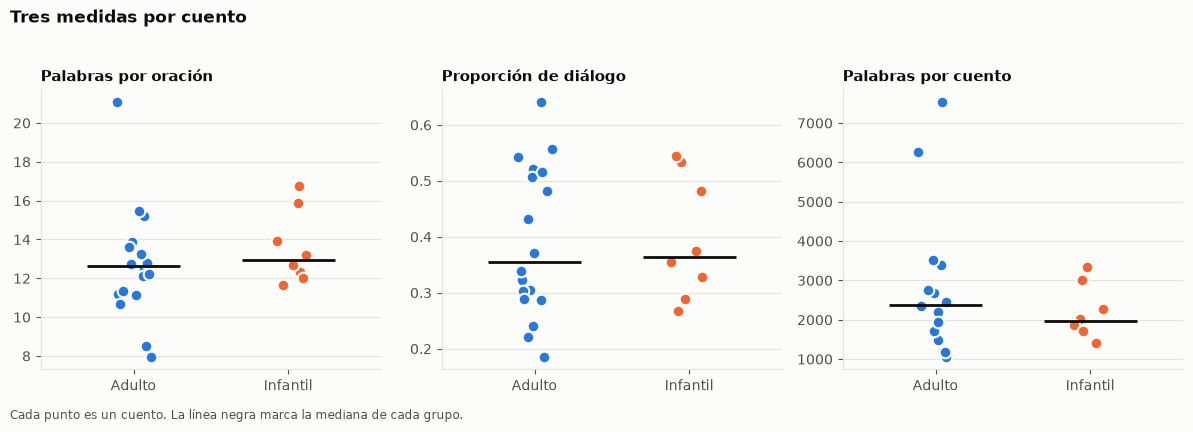

In [38]:
utils.graficar_puntos_por_cuento(
    tabla=corpus,
    columnas=medidas,
    titulos=["Palabras por oración", "Proporción de diálogo", "Palabras por cuento"],
    titulo_general="Tres medidas por cuento",
)

Complementamos el gráfico con las medianas y los rangos de cada grupo.

In [39]:
resumen_por_grupo = corpus.groupby("grupo")[medidas].agg(["median", "min", "max"])
display(resumen_por_grupo.round(2))

palabras_por_oración               proporción_de_diálogo              \
                       median    min    max                median   min   max   
grupo                                                                           
adulto                  12.61   7.96  21.07                  0.35  0.19  0.64   
infantil                12.93  11.68  16.76                  0.36  0.27  0.54   

         cantidad_de_palabras              
                       median   min   max  
grupo                                      
adulto                 2370.5  1061  7531  
infantil               1964.0  1405  3351

- **Observación:** las medianas muestran oraciones apenas más largas en los cuentos infantiles (12,93 contra 12,61 palabras) y una proporción de diálogo casi igual (0,36 contra 0,35). Los cuentos adultos tienen mayor mediana de longitud (2.371 contra 1.964 palabras), pero los rangos se superponen: los adultos van de 1.061 a 7.531 palabras y los infantiles de 1.405 a 3.351.
- **Interpretación:** la afirmación 1 queda contradicha, pero por una diferencia mínima frente a la dispersión de cada grupo (los cuentos adultos van de 8 a 21 palabras por oración). La afirmación 2 no se sostiene: las medianas son casi iguales. La afirmación 3 se sostiene como tendencia y no como regla: hay cuentos adultos más cortos que varios infantiles. Corregir «más cortas» por «más largas» sería el mismo error con el signo cambiado.
- **Límite:** el criterio para cortar oraciones y para detectar diálogo es simple, y con 8 y 18 cuentos, sin prueba estadística, solo podemos describir lo que se ve en estos cuentos, no afirmar que la diferencia exista en general.

**Regla del caso 5:** una conclusión escrita antes de los datos es una hipótesis, no un resultado. Si los datos la contradicen, lo correcto no es reemplazarla por la contraria: es medir cuánta diferencia hay frente a la dispersión.

### ✎ Para pensar

- ¿Qué tendría que pasar en el gráfico para que pudiéramos afirmar, con confianza razonable, que un grupo tiene oraciones más largas que el otro?
- ¿Qué cambia si definimos "diálogo" de otra manera, por ejemplo, contando también las frases entre comillas?

## Práctica: la ortografía de época

Hasta acá corregimos mediciones. Ahora van a auditar una por su cuenta. Los textos de Wikisource conservan la ortografía de 1917, con tilde en palabras como `fué`, `dió` o `vió`, que hoy se escriben sin ella. Veamos cómo reparte el corpus las dos grafías.

In [40]:
VARIANTES_DE_ORTOGRAFÍA = ["fue", "fué", "dio", "dió", "vio", "vió"]

filas_de_variantes = []
for variante in VARIANTES_DE_ORTOGRAFÍA:
    fila = {"variante": variante}
    for grupo in conteos_por_grupo:
        fila[grupo] = conteos_por_grupo[grupo][variante]
    filas_de_variantes.append(fila)

display(pd.DataFrame(filas_de_variantes))

,variante,adulto,infantil
0,fue,26,0
1,fué,47,19
2,dio,2,0
3,dió,8,11
4,vio,9,0
5,vió,24,23


- **Observación:** en el grupo adulto conviven las dos grafías (26 `fue` y 47 `fué`); en el infantil casi solo aparece la forma con tilde (19 `fué` y ninguna `fue`).
- **Interpretación:** un diccionario que incluya `fue` pero no `fué` pierde la mayoría de las apariciones, y las pierde en proporciones distintas en cada grupo: todas en el infantil y algo más de la mitad en el adulto.
- **Límite:** esto describe tres verbos; no sabemos cuántas otras palabras tienen el mismo problema.

### ✎ Práctica

Etapa 4: consigna abierta, sin código de partida. Escriban su resolución en la celda siguiente y expliquen en una celda de texto qué cambió.

In [41]:
# ─── Espacio de práctica ─────────────────────────────────────────────────────
#
# Consigna: normalicen la ortografía de época y vuelvan a contar.
#   1. Definan una función que reemplace fué por fue, dió por dio y vió por vio.
#   2. Cuenten otra vez las seis variantes de arriba por grupo.
#   3. Escriban en una celda de texto qué diferencia encuentran y a qué la atribuyen.
#   4. Verifiquen con una aserción que ya no queden formas con tilde.
#
# ─────────────────────────────────────────────────────────────────────────────

> **✎ Mentor reversible (bonus).** Hasta acá fuimos quienes aprenden. Ahora al revés: elijan el caso que más les costó entender y expliquen en treinta segundos, en voz alta, a quien tengan al lado, qué error tenía y cómo lo probamos. Si esa persona lo entiende, es porque ustedes ya lo entendieron de verdad.

## Checklist de validación

Estas cinco preguntas resumen lo que hicimos. Las vamos a aplicar a cada medición de acá en adelante.

| Pregunta | Error que detecta | Caso |
|---|---|---|
| ¿Qué mide realmente? | Un diccionario que mide el tema y no lo que dice medir | 2 |
| ¿Sobre qué denominador? | Una frecuencia relativa dividida por el total equivocado | 1 |
| ¿Qué pasa si cambio el parámetro? | Un `max_features` o un `min_df` que borran lo importante | 3 y 4 |
| ¿Qué contraejemplo la rompe? | Una conclusión que no resiste una concordancia o un caso | 2 y 5 |
| ¿Mi conclusión excede el n? | Afirmar con 4, 8 o 26 documentos más de lo que permiten | 4 y 5 |

## Limitaciones de lo que hicimos

- Contamos palabras con un criterio simple: no lematizamos ni normalizamos la ortografía.
- Los grupos son pequeños y de tamaños distintos: 18 y 8 cuentos.
- No hicimos ninguna prueba estadística: miramos distribuciones y medianas, y por eso no hablamos de significancia.
- Los diccionarios son criterios nuestros, no verdades del texto.

## Conexión con el próximo cuaderno

En el próximo cuaderno formulamos una hipótesis propia sobre estos dos volúmenes de Quiroga. Cada medición que propongamos tendrá que pasar por esta checklist antes de que le creamos.

### ✎ Diario de navegación

Cerramos mirando hacia adentro, no hacia el código. Respondan en una o dos líneas, para ustedes:

1. ¿Qué concepto de hoy les costó más encajar? ¿Por qué creen que se resistió?
2. Si tuvieran que explicarle este cuaderno a un colega en lo que dura un viaje en ascensor, ¿qué le dirían?

No hay respuesta correcta. Lo que escriban es el mapa de su propio recorrido.